In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

bands = ['delta', 'theta', 'alpha', 'beta', 'low_gamma']
metrics = ['exponent_z', 'offset_z']
all_feature_groups = bands + metrics

behavior_table = pd.read_csv('/home/hazel/shirvalkar/test-code-hazel/behavior_table_all_patients_newPC.csv')
ptIDs = ['RCS02', 'RCS03', 'RCS04', 'RCS05', 'RCS06', 'RCS07', 'RCS08', 'RCS09']

behavior_configs = {
    'nrs': {
        'column': 'nrs_z',
        'default_thresh': (50, 50),
        'patient_thresh': {
            'RCS02': (30, 30), 'RCS04': (30, 30), 'RCS03': (10, 30),
            'RCS06': (10, 10), 'RCS05': (20, 30),
        },
        'exclude_patients': [],
    },
    'mpq_affective': {
        'column': 'affective_z',
        'default_thresh': (50, 50),
        'patient_thresh': {
            'RCS02': (30, 30), 'RCS03': (5, 10), 'RCS06': (10, 10),
            'RCS07': (10, 10), 'RCS05': (20, 30),
        },
        'exclude_patients': ['RCS04', 'RCS09'],
    },
    'mpq_somatic': {
        'column': 'somatic_z',
        'default_thresh': (49, 49),
        'patient_thresh': {},
        'exclude_patients': [],
    },
    'affective_pc1': {
        'column': 'new_affective_PC1',
        'default_thresh': (50, 50),
        'patient_thresh': {},
        'exclude_patients': [],
    },
    'sensory_pc1': {
        'column': 'new_sensory_PC1',
        'default_thresh': (50, 50),
        'patient_thresh': {},
        'exclude_patients': [],
    },
}

def build_roi_level_features(ptID, behavior_table, feature_type, behavior_key, config):
    if ptID in config['exclude_patients']:
        return None

    subset = behavior_table[behavior_table['ptID'] == ptID].copy()
    behavior_series = subset[config['column']]

    thresh_low, thresh_high = config['patient_thresh'].get(ptID, config['default_thresh'])

    label, _, _, _ = split_dep_new(behavior_series, thresh_low, thresh_high)
    subset['behavior_label'] = label

    records_df = pd.read_pickle(f"/home/hazel/shirvalkar/pain-data/Stage1-test/{ptID}/records_df_fooof_{ptID}.pkl")
    feat_df = pd.read_csv('/home/hazel/shirvalkar/test-code-hazel/perchannel_psdfeat_and_aperiodic_df.csv')
    feat_df = feat_df[feat_df['ptID'] == ptID]
    records_df['roi'] = records_df['ch_label'].str.replace(r'_\d+$', '', regex=True)
    roi_select = records_df['roi'].unique()

    merged = records_df.merge(subset, on='trial_idx', suffixes=('', '_dup')) \
                        .merge(feat_df, on=['trial_idx', 'ch_label'], suffixes=('', '__dup'))
    merged = merged[[c for c in merged.columns if not c.endswith('_dup')]]
    merged_filt = merged[(merged['r2'] >= 0.9) & (merged['behavior_label'] != 'neutral') & (merged['roi'].isin(roi_select))]
    values = bands if feature_type == 'periodic' else metrics

    roi_level = merged_filt.groupby(['trial_idx', 'roi'])[values].mean().reset_index()
    wide = roi_level.pivot_table(index='trial_idx', columns='roi', values=values)
    wide.columns = [f'{v}_{roi}' for v, roi in wide.columns]

    y = merged_filt.drop_duplicates('trial_idx').set_index('trial_idx').loc[wide.index, 'behavior_label']

    wide['ptID'] = ptID
    wide['behavior_label'] = y

    return wide.reset_index()


def build_pooled_data(ptIDs, behavior_table, feature_type, behavior_key, config, coverage_thresh=0.625, savemeta = False):
    pt_tables = [
        build_roi_level_features(pt, behavior_table, feature_type, behavior_key, config)
        for pt in ptIDs
    ]
    pt_tables = [t for t in pt_tables if t is not None]

    pooled = pd.concat(pt_tables, ignore_index=True)
    feat_cols = [c for c in pooled.columns if c not in ('trial_idx', 'ptID', 'behavior_label')]
    pooled = pooled[pooled['behavior_label'].notna()]

    coverage = pooled.groupby('ptID')[feat_cols].apply(lambda g: g.notna().any())
    coverage_frac = coverage.mean()
    keep_cols = coverage_frac[coverage_frac >= coverage_thresh].index.tolist()

    print(f'{behavior_key}/{feature_type}:  {len(keep_cols)}/{len(feat_cols)}  (coverage >= {coverage_thresh}), '
          f'{pooled["ptID"].nunique()} patients, {len(pooled)} trials')

    X = pooled[keep_cols]
    y = pooled['behavior_label']
    groups = pooled['ptID']

    if savemeta:
        return X, y, groups, keep_cols, pooled[['ptID', 'trial_idx']]
    return X, y, groups, keep_cols

In [2]:
def split_dep_new(series, percent1, percent2=None):
    if percent2 is None:
        percent2 = percent1
    X = np.asarray(series)
    labels = pd.Series(['neutral'] * len(X), index=series.index)
    thresh_low = np.percentile(X, percent1)
    thresh_high = np.percentile(X, 100 - percent2)
    low = np.where(X <= thresh_low)[0]
    high = np.where(X >= thresh_high)[0]
    labels.iloc[high] = 'high'
    labels.iloc[low] = 'low'
    return labels, len(high), len(np.where((X > thresh_low) & (X < thresh_high))[0]), len(low)

def parse_metric_feat_name(name, metrics):
    for m in sorted(metrics, key=len, reverse=True):
        prefix = m + '_'
        if name.startswith(prefix):
            ch_label = name[len(prefix):]
            roi = re.sub(r'_\d+$', '', ch_label)
            return m, roi, ch_label
    raise ValueError(f"Feature name doesn't match any known band/metric: {name}")

In [3]:
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import seaborn as sns
import os, json, datetime
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, precision_score, recall_score, f1_score

BASE = '/home/hazel/shirvalkar/test-code-hazel'
FIGDIR = f'{BASE}/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026'
METADIR = f'{BASE}/logreg_results_pickle/run_metadata'

def align_pca_sign(pca, reference_components):
    aligned = pca.components_.copy()
    for i in range(aligned.shape[0]):
        if np.dot(aligned[i], reference_components[i]) < 0:
            aligned[i] = -aligned[i]
    return aligned

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.impute import SimpleImputer

def build_clf(n_components, strategy='mean', fill_value=None, C=None):
    imp = SimpleImputer(strategy=strategy, fill_value=fill_value) if strategy == 'constant' else SimpleImputer(strategy=strategy)
    steps = [imp, StandardScaler()]
    if n_components != 0:
        steps.append(PCA(n_components=n_components, random_state=42))
    if C is None:
        steps.append(LogisticRegressionCV(
            penalty='l2', solver='liblinear', cv=5, random_state=42,
            Cs=10, scoring='roc_auc', max_iter=1000))
    else:
        steps.append(LogisticRegression(
            penalty='l2', solver='liblinear', C=C, max_iter=1000))
    return make_pipeline(*steps)


In [4]:
def balanced_bootstrap_idx(groups, y, n_per_patient, rng):
    g, yy = np.asarray(groups), np.asarray(y)
    idx = []
    for pt in np.unique(g): # ptID
        for lab in np.unique(yy): # high, low
            pool = np.where((g == pt) & (yy == lab))[0]
            if len(pool):
                idx.append(rng.choice(pool, size=n_per_patient // 2, replace=True))
    return np.concatenate(idx)

In [5]:
def coef_toward_high(lr, pos='high'):
    return lr.coef_.ravel() * (1 if lr.classes_[1] == pos else -1)

def to_feature_space(clf, ref_components, lr_name):
    b = coef_toward_high(clf.named_steps[lr_name])
    if 'pca' in clf.named_steps:
        b = align_pca_sign(clf.named_steps['pca'], ref_components).T @ b
    return b

def fit_eval_balanced_bootstrap(X_train, y_train, g_train, X_test, y_test, g_test,
                                n_components, n_boot, rng, ref_components=None,
                                n_per_pt_train=None, n_per_pt_test=None, pos='high', record=None):
    base = build_clf(n_components,strategy='constant',fill_value=0).fit(X_train, y_train)
    C_fixed = float(base.named_steps['logisticregressioncv'].C_[0])        # 该折选一次,折内所有重复共用
    n_per_pt_train = n_per_pt_train or int(g_train.value_counts().median())
    n_per_pt_test = n_per_pt_test or int(g_test.value_counts().median())

    n_tr, n_te = len(X_train), len(X_test)
    drawn_tr, drawn_te = np.zeros(n_tr), np.zeros(n_te)
    pred_high, sum_proba = np.zeros(n_te), np.zeros(n_te)
    aucs, betas, yt_all, yp_all = [], [], [], []

    for _ in range(n_boot):
        bi_tr = balanced_bootstrap_idx(g_train, y_train, n_per_pt_train, rng)
        bi_te = balanced_bootstrap_idx(g_test, y_test, n_per_pt_test, rng)
        clf = build_clf(n_components, strategy='constant', fill_value=0, C=C_fixed).fit(X_train.iloc[bi_tr], y_train.iloc[bi_tr])
        pos_idx = list(clf.classes_).index(pos)
        y_b = y_test.iloc[bi_te]
        proba = clf.predict_proba(X_test.iloc[bi_te])[:, pos_idx]
        pred = clf.predict(X_test.iloc[bi_te])

        aucs.append(roc_auc_score((y_b == pos).astype(int), proba))
        yt_all.append(y_b.values); yp_all.append(pred)
        betas.append(to_feature_space(clf, ref_components, 'logisticregression'))

        drawn_tr += np.bincount(bi_tr, minlength=n_tr)
        drawn_te += np.bincount(bi_te, minlength=n_te)
        pred_high += np.bincount(bi_te, weights=(pred == pos).astype(float), minlength=n_te)
        sum_proba += np.bincount(bi_te, weights=proba, minlength=n_te)

    if record is not None:
        record.update(C=C_fixed, n_per_pt_train=n_per_pt_train, n_per_pt_test=n_per_pt_test,
                      n_train_boot=len(bi_tr), n_test_boot=len(bi_te),     # 每次重复实际抽到的总 trial 数
                      n_drawn_train=drawn_tr, n_drawn_test=drawn_te,
                      n_pred_high=pred_high, sum_proba_high=sum_proba)
    return np.mean(aucs), np.mean(betas, axis=0), np.concatenate(yt_all), np.concatenate(yp_all)

In [6]:
def pooled_pca_logistic_stability(X, y, groups, behavior_label, feature_type_label, pt=None,
                                  n_components=5, n_splits=5, random_state=42, savepath=False,
                                  bootstrap=False, n_boot=1, records=None):          # CHANGED: +records
    clf_full = build_clf(n_components,strategy='constant',fill_value=0)
    clf_full.fit(X, y)
    full_C = float(clf_full.named_steps['logisticregressioncv'].C_[0])                 # NEW
    ref_components = clf_full.named_steps['pca'].components_ if n_components != 0 else None   # NEW

    rng = np.random.RandomState(random_state)
    if bootstrap:
        print(f"bootstrap n={n_boot}, num_trial={int(groups.value_counts().median())}\n")
        bs = []
        for _ in range(n_boot):
            bi = balanced_bootstrap_idx(groups, y, int(groups.value_counts().median()), rng)
            clf = build_clf(n_components, strategy='constant', fill_value=0, C=full_C).fit(X.iloc[bi], y.iloc[bi])
            bs.append(to_feature_space(clf, ref_components, 'logisticregression'))     # CHANGED
        full_sample_coef = np.mean(bs, axis=0)
    else:
        full_sample_coef = to_feature_space(clf_full, ref_components, 'logisticregressioncv')   # CHANGED

    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    fold_scores = []
    fold_coefs = []
    oof_proba = np.full(len(y), np.nan)
    oof_pred = np.empty(len(y), dtype=object)
    boot_true, boot_pred = [], []
    patient_compositions = []
    patient_order = sorted(groups.dropna().unique())
    fold_records = []                                                                   # NEW

    for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X, y)):                   # CHANGED: enumerate
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        group_train, group_test = groups.iloc[train_idx], groups.iloc[test_idx]

        if bootstrap:
            rec = {}                                                                    # NEW
            auc, beta_fold, yt, yp = fit_eval_balanced_bootstrap(
                X_train, y_train, group_train, X_test, y_test, group_test, n_components, n_boot, rng,
                ref_components=ref_components, record=rec)                              # CHANGED
            fold_scores.append(auc)
            fold_coefs.append(beta_fold)
            boot_true.append(yt)
            boot_pred.append(yp)
        else:
            train_counts = group_train.value_counts(normalize=True).reindex(patient_order, fill_value=0) * 100
            test_counts = group_test.value_counts(normalize=True).reindex(patient_order, fill_value=0) * 100
            patient_compositions.append((train_counts, test_counts))

            clf_fold = build_clf(n_components, strategy='constant', fill_value=0)
            clf_fold.fit(X_train, y_train)
            y_proba = clf_fold.predict_proba(X_test)
            pos_idx = list(clf_fold.classes_).index('high')
            auc = roc_auc_score((y_test == 'high').astype(int), y_proba[:, pos_idx])
            fold_scores.append(auc)
            oof_proba[test_idx] = y_proba[:, pos_idx]
            oof_pred[test_idx] = clf_fold.predict(X_test)

            beta_fold = to_feature_space(clf_fold, ref_components, 'logisticregressioncv')   # CHANGED
            fold_coefs.append(beta_fold)

            rec = dict(C=float(clf_fold.named_steps['logisticregressioncv'].C_[0]),     # NEW
                       n_per_pt_train=np.nan, n_per_pt_test=np.nan,
                       n_train_boot=len(train_idx), n_test_boot=len(test_idx),
                       n_drawn_train=np.ones(len(train_idx)), n_drawn_test=np.ones(len(test_idx)),
                       n_pred_high=(oof_pred[test_idx] == 'high').astype(float),
                       sum_proba_high=y_proba[:, pos_idx])

        fold_records.append(dict(rec, fold=fold_idx, auc=auc, coef=beta_fold,           # NEW
                                 train_idx=train_idx, test_idx=test_idx))

    fold_scores = np.array(fold_scores)
    fold_coefs = np.array(fold_coefs)

    print(f'{behavior_label}_{feature_type_label} pooled model — out-of-sample AUC (5KFold): {fold_scores.mean():.3f} ± {fold_scores.std():.3f}')

    coef_mean = fold_coefs.mean(axis=0)
    coef_std = fold_coefs.std(axis=0)
    with np.errstate(divide='ignore', invalid='ignore'):
        coef_snr = coef_mean / coef_std
    sign_consistency = abs(sum(fold_coefs>=0)-sum(fold_coefs<=0))/fold_coefs.shape[0]
    print(sign_consistency)

    stability_df = pd.DataFrame({
        'feature_type': feature_type_label,
        'feature': X.columns,
        'full_sample_coef': full_sample_coef,
        'cv_mean_coef': coef_mean,
        'cv_std_coef': coef_std,
        'cv_snr': coef_snr,
        'sign_consistency': sign_consistency
    })
    stability_df['roi'] = [s.split('_')[-1] for s in stability_df['feature']]
    stability_df['feature_group'] = [re.match(r'^[a-z_]*', s).group()[:-1] for s in stability_df['feature']]

    if records is not None:                                                             # NEW
        records.update(folds=fold_records, full_C=full_C, full_sample_coef=full_sample_coef,
                       bootstrap=bootstrap, n_boot=(n_boot if bootstrap else 1), n_splits=n_splits)

    ## PLOTTING(以下不变)
    # from pathlib import Path
    # if bootstrap:
    #     y_eval, pred_eval = np.concatenate(boot_true), np.concatenate(boot_pred)
    #     savedir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/bootstrap/confusion-matrix'
    #     plot_confusion_matrix(y_eval, pred_eval, fold_scores, title=f'{behavior_label}_{feature_type_label}_pooled_boot{n_boot}', n_boot=n_boot, savedir=savedir)
    # else:
    #     if pt == None:
    #         savedir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/confusion-matrix'
    #         Path(savedir).mkdir(exist_ok=True)
    #     else:
    #         savedir = f'/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/confusion-matrix/individual-pt/{pt}'
    #         Path(savedir).mkdir(parents=True, exist_ok=True)
    #     
    # fusion_matrix(y, oof_pred, fold_scores, title=f'{behavior_label}_{feature_type_label}_pooled', savedir=savedir)

    return stability_df, fold_scores

In [7]:
from pathlib import Path

def build_metadata_tables(records, stability_df, X, y, meta, behavior_label, feature_type_label,
                          config, behavior_table):
    score_col = config['column']
    base = (meta.reset_index(drop=True)
              .assign(row_idx=np.arange(len(X)), label=y.values)
              .merge(behavior_table[['ptID', 'trial_idx', score_col]], on=['ptID', 'trial_idx'], how='left')
              .rename(columns={score_col: 'raw_score'}))
    assert len(base) == len(X), 'merge 之后行数变了:behavior_table 里 (ptID, trial_idx) 有重复'
    ids = {'behavior': behavior_label, 'feature_type': feature_type_label}

    # ---- 表1: fold_table ----
    fold_rows = [dict(ids, fold=-1, bootstrap=records['bootstrap'], n_boot=records['n_boot'],      # 全数据拟合
                      n_train=len(X), C=records['full_C'], train_frac_high=(y == 'high').mean())]
    # ---- 表2: trial_table ----
    trial_parts = []
    for f in records['folds']:
        tr, te = base.iloc[f['train_idx']].copy(), base.iloc[f['test_idx']].copy()
        tr['split'], tr['n_drawn'] = 'train', f['n_drawn_train']
        te['split'], te['n_drawn'] = 'test', f['n_drawn_test']
        te['n_pred_high'] = f['n_pred_high']
        te['n_pred_low'] = f['n_drawn_test'] - f['n_pred_high']
        te['sum_proba_high'] = f['sum_proba_high']
        for part in (tr, te):
            part['fold'] = f['fold']
        trial_parts += [tr, te]

        fold_rows.append(dict(ids, fold=f['fold'], bootstrap=records['bootstrap'], n_boot=records['n_boot'],
                              n_train=len(tr), n_test=len(te),
                              n_per_pt_train=f['n_per_pt_train'], n_per_pt_test=f['n_per_pt_test'],
                              n_train_boot=f['n_train_boot'], n_test_boot=f['n_test_boot'],
                              C=f['C'], auc=f['auc'],
                              train_frac_high=(tr['label'] == 'high').mean(),
                              test_frac_high=(te['label'] == 'high').mean()))
    trial_table = pd.concat(trial_parts, ignore_index=True)
    trial_table = pd.concat([pd.DataFrame(ids, index=trial_table.index), trial_table], axis=1)
    trial_table = trial_table[['behavior', 'feature_type', 'fold', 'split', 'row_idx', 'ptID', 'trial_idx',
                               'raw_score', 'label', 'n_drawn', 'n_pred_high', 'n_pred_low', 'sum_proba_high']]

    # ---- 表3: coef_table ----
    fmap = stability_df.set_index('feature')[['feature_group', 'roi']]
    coef_parts = []
    for fold, coef in [(f['fold'], f['coef']) for f in records['folds']] + [(-1, records['full_sample_coef'])]:
        d = pd.DataFrame({'feature': X.columns, 'coef': coef}).join(fmap, on='feature')
        d['fold'] = fold
        coef_parts.append(d)
    coef_table = pd.concat(coef_parts, ignore_index=True)
    coef_table = pd.concat([pd.DataFrame(ids, index=coef_table.index), coef_table], axis=1)
    coef_table = coef_table[['behavior', 'feature_type', 'fold', 'feature', 'feature_group', 'roi', 'coef']]

    return {'fold_table': pd.DataFrame(fold_rows), 'trial_table': trial_table, 'coef_table': coef_table}

def save_model_metadata(outdir, tables, settings):
    Path(outdir).mkdir(parents=True, exist_ok=True)
    b, ft = tables['fold_table'].loc[0, ['behavior', 'feature_type']]
    pd.to_pickle({**tables, 'settings': settings}, f'{outdir}/{b}_{ft}_metadata.pickle')

def load_all_metadata(outdir):
    out = {'fold_table': [], 'trial_table': [], 'coef_table': []}
    for p in sorted(Path(outdir).glob('*_metadata.pickle')):
        d = pd.read_pickle(p)
        for k in out:
            out[k].append(d[k])
    return {k: pd.concat(v, ignore_index=True) for k, v in out.items()}

In [30]:
settings = dict(n_splits=10, random_state=42, n_components=0, bootstrap=True, n_boot=1000)
metadir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/metadata_nboot1000/zero_filling'

all_stability_rows = []
# all_ablation_rows = []
all_auc_rows = []
for behavior_key, config in behavior_configs.items():
    for feature_type in ['periodic', 'aperiodic']:
        X, y, groups, feat_cols, meta = build_pooled_data(
            ptIDs, behavior_table, feature_type, behavior_key, config, savemeta=True)   # CHANGED

        rec = {}                                                                             # NEW
        stability_df, fold_scores = pooled_pca_logistic_stability(
            X, y, groups, behavior_key, feature_type, n_components=0, n_splits=10,
            bootstrap=True, n_boot=1000, records=rec)                                         # CHANGED

        tables = build_metadata_tables(rec, stability_df, X, y, meta, behavior_key, feature_type,
                                       config, behavior_table)                               # NEW
        save_model_metadata(metadir, tables, settings)                                       # NEW

        stability_df['behavior'] = behavior_key
        all_stability_rows.append(stability_df)
        all_auc_rows.append({
            'behavior': behavior_key, 'feature_type': feature_type,
            'auc_mean': fold_scores.mean(), 'auc_std': fold_scores.std(), 'whole_auc': fold_scores,
            'n_trials': X.shape[0], 'n_patients': groups.nunique(),
        })

stability_all_behaviors = pd.concat(all_stability_rows, ignore_index=True)
auc_summary_all_behaviors = pd.DataFrame(all_auc_rows)
pd.to_pickle(stability_all_behaviors, f'{metadir}/NEW1118_NOPCA_10fold_pooled_5behavior_BOOTSTRAP_ZEROFILLING_stability.pickle')
pd.to_pickle(auc_summary_all_behaviors, f'{metadir}/NEW1118_NOPCA_10fold_pooled_5behavior_BOOTSTRAP_ZEROFILLING_auc_summary.pickle')


nrs/periodic:  75/100  (coverage >= 0.625), 8 patients, 495 trials
bootstrap n=1000, num_trial=53

nrs_periodic pooled model — out-of-sample AUC (5KFold): 0.675 ± 0.086
[0.6 0.8 0.2 0.8 1.  1.  1.  1.  0.6 0.2 1.  1.  0.2 0.2 0.2 0.8 1.  1.
 1.  1.  0.8 1.  1.  0.4 0.8 0.8 0.8 1.  1.  1.  1.  0.4 0.8 1.  0.2 1.
 1.  0.8 1.  0.2 1.  0.8 0.8 1.  1.  0.8 0.4 0.6 0.8 1.  1.  1.  1.  0.6
 0.4 0.8 1.  1.  1.  1.  1.  0.8 1.  0.8 1.  0.2 1.  1.  0.6 1.  1.  1.
 0.8 0.4 0.8]
nrs/aperiodic:  30/40  (coverage >= 0.625), 8 patients, 495 trials
bootstrap n=1000, num_trial=53

nrs_aperiodic pooled model — out-of-sample AUC (5KFold): 0.551 ± 0.049
[1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  0.4 1.
 1.  1.  1.  1.  1.  1.  1.  1.  1.  0.8 0.  1. ]
mpq_affective/periodic:  70/95  (coverage >= 0.625), 6 patients, 281 trials
bootstrap n=1000, num_trial=44

mpq_affective_periodic pooled model — out-of-sample AUC (5KFold): 0.722 ± 0.126
[1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1. 

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from pathlib import Path

C_TRAIN, C_TEST = '#446F85', '#E07B5D'
C_HIGH, C_LOW = '#E74C3C', '#3498DB'

def plot_model_folds(fold_table, trial_table, behavior, feature_type,reference_table,
                     after_bootstrap=True, patient_after_bootstrap=False,
                     bins=25, density=True, patient_order=None, ncols_pt=4,
                     row_h=2.3, savedir=None, show=True, sort_by=None):
    ft = (fold_table[(fold_table.behavior == behavior) & (fold_table.feature_type == feature_type)
                     & (fold_table.fold >= 0)].sort_values('fold').set_index('fold'))
    if sort_by is not None:                                           # NEW: 'auc' / 'C' / 'test_frac_high' ...
        ft = ft.sort_values(sort_by, ascending=False)
    tt = trial_table[(trial_table.behavior == behavior) & (trial_table.feature_type == feature_type)].copy()
    folds, nf = ft.index.tolist(), len(ft)
    n_boot = int(ft['n_boot'].iloc[0])

    tt['w'] = tt['n_drawn'] / n_boot            # 每次重复里的期望抽中次数
    tt['one'] = 1.0                             # 原始 trial,每个算 1
    w_col = 'w' if after_bootstrap else 'one'                       # 第 1、3 列
    pw_col = 'w' if patient_after_bootstrap else 'one'              # 第 4 列

    reference = reference_table[['ptID', 'trial_idx', 'raw_score']].drop_duplicates(['ptID', 'trial_idx'])

    patient_scores = {
        pt: reference.loc[
            reference.ptID == pt, 'raw_score'
        ].dropna().values
        for pt in patient_order
    }

    if patient_order is None:
        patient_order = sorted(tt['ptID'].unique())
    nrows_pt = int(np.ceil(len(patient_order) / ncols_pt))
    edges = np.linspace(tt['raw_score'].min(), tt['raw_score'].max(), bins + 1)   # 所有折共用同一组 bin

    ratios = [3.0, 1.9, 2.2, 2.4, 2.4, 2.1, 2.3]
    fig_w, fig_h = 24, row_h * nf + 1.6
    fig = plt.figure(figsize=(fig_w, fig_h))
    gs = fig.add_gridspec(nf, 7, width_ratios=ratios, hspace=0.55, wspace=0.35,
                          left=0.05, right=0.99, top=1 - 1.1 / fig_h, bottom=0.6 / fig_h)
    col_titles = ['Raw score', 'Total n', 'True label (fraction)', 'Patient contribution: train',
                  'Patient contribution: test', 'Predicted vs true (test)', 'AUC / regularization']

    def tiles(ax, sub):
        n_by = sub.groupby('ptID')[pw_col].sum().reindex(patient_order, fill_value=0)
        pct = n_by / n_by.sum() * 100
        ax.set_xlim(0, ncols_pt); ax.set_ylim(0, nrows_pt); ax.axis('off')
        for j, pt in enumerate(patient_order):
            rr, cc = divmod(j, ncols_pt); y0 = nrows_pt - 1 - rr
            ax.add_patch(Rectangle((cc, y0), 1, 1, facecolor=plt.cm.Blues(min(pct[pt] / 40, 1)),
                                   edgecolor='white', linewidth=2))
            ax.text(cc + .5, y0 + .5, f'{pt}\n{n_by[pt]:.0f}\n{pct[pt]:.0f}%', ha='center', va='center',
                    fontsize=7, color='white' if pct[pt] > 25 else 'black')

    for r, k in enumerate(folds):
        d = tt[tt.fold == k]
        tr, te = d[d.split == 'train'], d[d.split == 'test']
        row = ft.loc[k]
        ax = [fig.add_subplot(gs[r, c]) for c in range(7)]
        if r == 0:
            for a, t in zip(ax, col_titles):
                a.set_title(t, fontsize=10, fontweight='bold')

        # 1. raw score histogram
        for sub, col, lab in [(tr, C_TRAIN, 'train'), (te, C_TEST, 'test')]:
            ax[0].hist(sub['raw_score'], bins=edges, weights=sub[w_col], density=density,
                       alpha=.55, color=col, label=lab)
        ax[0].set_xlim(edges[0], edges[-1]); ax[0].set_yticks([])
        ax[0].text(-0.04, .5, f'Fold {k}', transform=ax[0].transAxes, ha='right', va='center',
                   fontsize=11, fontweight='bold')
        if r < nf - 1:
            ax[0].set_xticklabels([])
        if r == 0:
            ax[0].legend(fontsize=7, frameon=False)

        # 2. total n
        ax[1].axis('off')
        ax[1].text(0.05, .72, f"train\norig  {int(row.n_train):,}\nboot  {int(row.n_train_boot):,}",
                   color=C_TRAIN, fontsize=10, va='center', transform=ax[1].transAxes)
        ax[1].text(0.05, .25, f"test\norig  {int(row.n_test):,}\nboot  {int(row.n_test_boot):,}",
                   color=C_TEST, fontsize=10, va='center', transform=ax[1].transAxes)

        # 3. true high/low (fraction, 数量标在柱子上)
        for j, (sub, col, lab) in enumerate([(tr, C_TRAIN, 'train'), (te, C_TEST, 'test')]):
            cnt = np.array([sub.loc[sub.label == l, w_col].sum() for l in ['high', 'low']])
            frac = cnt / cnt.sum() if cnt.sum() > 0 else cnt
            xs = np.arange(2) + (-0.2 if j == 0 else 0.2)
            ax[2].bar(xs, frac, width=.38, color=col, label=lab)
            for x, f_, c_ in zip(xs, frac, cnt):
                ax[2].text(x, f_ + .02, f'{c_:.0f}', ha='center', fontsize=7)
        ax[2].axhline(.5, ls=':', c='gray'); ax[2].set_ylim(0, 1.15)
        ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(['high', 'low'])
        if r == 0:
            ax[2].legend(fontsize=7, frameon=False, loc='upper right')

        # 4. patient contribution
        tiles(ax[3], tr); tiles(ax[4], te)

        # 5. predicted vs true (test);预测只在被抽中的 trial 上有定义,所以真实数量也用 n_drawn/n_boot
        pred = [te['n_pred_high'].sum() / n_boot, te['n_pred_low'].sum() / n_boot]
        true = [te.loc[te.label == l, 'w'].sum() for l in ['high', 'low']]
        ax[5].bar([0, 1], pred, width=.6, color=[C_HIGH, C_LOW], alpha=.85)
        ax[5].bar([0, 1], true, width=.6, fill=False, edgecolor='k', linestyle='--', linewidth=1.3)
        for x, p_, t_ in zip([0, 1], pred, true):
            ax[5].text(x, max(p_, t_) * 1.02, f'{p_:.0f} / {t_:.0f}', ha='center', fontsize=7)
        ax[5].set_ylim(0, max(pred + true) * 1.2)
        ax[5].set_xticks([0, 1]); ax[5].set_xticklabels(['pred high', 'pred low'], fontsize=8)
        if r == 0:
            ax[5].legend(handles=[Patch(facecolor='gray', alpha=.85, label='predicted'),
                                  Patch(fill=False, edgecolor='k', linestyle='--', label='true')],
                         fontsize=7, frameon=False, loc='upper right')

        # 6. AUC / regularization
        ax[6].barh([0], [row.auc], height=.6, color=C_TRAIN if row.auc >= .5 else C_HIGH)
        ax[6].axvline(.5, ls='--', c='gray'); ax[6].set_xlim(0, 1); ax[6].set_ylim(-1.6, 1.6); ax[6].set_yticks([])
        ax[6].text(.5, .97, f'AUC = {row.auc:.3f}', transform=ax[6].transAxes, ha='center', va='top',
                   fontsize=11, fontweight='bold')
        ax[6].text(.5, .03, f'C = {row.C:.3g}\nlog10 C = {np.log10(row.C):.2f}', transform=ax[6].transAxes,
                   ha='center', va='bottom', fontsize=9)

    mode = 'after bootstrap' if after_bootstrap else 'original trials'
    fig.suptitle(f'{behavior} — {feature_type}   |   mean AUC {ft.auc.mean():.3f} ± {ft.auc.std():.3f}'
                 f'   |   {mode} (n_boot={n_boot})', fontsize=14, y=0.995)
    if savedir:
        Path(savedir).mkdir(parents=True, exist_ok=True)
        fig.savefig(f'{savedir}/{behavior}_{feature_type}_folds.png', dpi=200, bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close(fig)
    return fig

In [32]:
figdir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/metadata_nboot1000/zero_filling/plots'
metadir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/metadata_nboot1000/zero_filling'
m = load_all_metadata(metadir)

all_pts = sorted(m['trial_table']['ptID'].unique())
for (b, ft_), _ in m['fold_table'].groupby(['behavior', 'feature_type']):
    plot_model_folds(m['fold_table'], m['trial_table'], b, ft_,
                     patient_order=all_pts, savedir=figdir, show=False, patient_after_bootstrap=True,sort_by='auc')

TypeError: plot_model_folds() missing 1 required positional argument: 'reference_table'

In [8]:
def build_pooled_data_ref(ptIDs, behavior_table, feature_type, behavior_key,
                      config, coverage_thresh=0.625):
    pt_tables = [
        build_roi_level_features(pt, behavior_table, feature_type, behavior_key, config)
        for pt in ptIDs
    ]
    pt_tables = [t for t in pt_tables if t is not None]
    pooled = pd.concat(pt_tables, ignore_index=True)

    feat_cols = [c for c in pooled.columns if c not in ('trial_idx', 'ptID', 'behavior_label')]
    pooled = pooled[pooled['behavior_label'].notna()].copy()

    coverage = pooled.groupby('ptID')[feat_cols].apply(lambda g: g.notna().any())
    coverage_frac = coverage.mean()
    keep_cols = coverage_frac[coverage_frac >= coverage_thresh].index.tolist()

    print(f'{behavior_key}/{feature_type}: 保留 {len(keep_cols)}/{len(feat_cols)} 列 '
          f'(coverage >= {coverage_thresh}), {pooled["ptID"].nunique()} patients, {len(pooled)} trials')

    X = pooled[keep_cols]
    y = pooled['behavior_label']
    groups = pooled['ptID']
    meta = pooled[['ptID', 'trial_idx']].copy()

    return X, y, groups, keep_cols, meta, pooled

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from pathlib import Path

BAND_ORDER = ['delta', 'theta', 'alpha', 'beta', 'low_gamma', 'exponent_z', 'offset_z']

def _default_roi_order(rois):
    def key(r):
        side, _, area = str(r).partition(' ')
        return ({'L': 0, 'R': 1}.get(side, 2), area)
    return sorted(rois, key=key)

def plot_model_folds(
    fold_table, trial_table, coef_table, reference_table, behavior, feature_type,
    after_bootstrap=True, patient_after_bootstrap=False,
    bins=25, patient_bins=12, density=True, patient_order=None, ncols_pt=4, row_h=2.3,
    savedir=None, show=True, sort_by=None, ascending=False,
    roi_order=None, feature_group_order=None, coef_clip_pct=100, c_range=(-4, 4)
):
    # ---- 1. 数据筛选 ----
    ft = (fold_table[(fold_table.behavior == behavior) & (fold_table.feature_type == feature_type)
                     & (fold_table.fold >= 0)].sort_values('fold').set_index('fold'))
    if sort_by is not None:
        ft = ft.sort_values(sort_by, ascending=ascending)
    tt = trial_table[(trial_table.behavior == behavior) & (trial_table.feature_type == feature_type)].copy()
    ct = coef_table[(coef_table.behavior == behavior) & (coef_table.feature_type == feature_type)
                    & (coef_table.fold >= 0)].copy()
    folds, nf = ft.index.tolist(), len(ft)
    n_boot = int(ft['n_boot'].iloc[0])

    tt['w'] = tt['n_drawn'] / n_boot
    tt['one'] = 1.0
    w_col = 'w' if after_bootstrap else 'one'
    pw_col = 'w' if patient_after_bootstrap else 'one'

    if patient_order is None:
        patient_order = sorted(reference_table['ptID'].unique())
    nrows_pt = int(np.ceil(len(patient_order) / ncols_pt))
    edges = np.linspace(tt['raw_score'].min(), tt['raw_score'].max(), bins + 1)

    reference = reference_table[['ptID', 'trial_idx', 'raw_score']].drop_duplicates(['ptID', 'trial_idx'])
    patient_scores = {pt: reference.loc[reference.ptID == pt, 'raw_score'].dropna().values for pt in patient_order}

    # ---- 2. coefficient 矩阵:行 = band/metric,列 = ROI(横向排,比例更合适) ----
    if roi_order is None:
        roi_order = _default_roi_order(ct['roi'].dropna().unique())
    if feature_group_order is None:
        present = list(pd.unique(ct['feature_group'].dropna()))
        feature_group_order = [g for g in BAND_ORDER if g in present] + [g for g in present if g not in BAND_ORDER]
    n_roi, n_grp = len(roi_order), len(feature_group_order)
    n_left = sum(str(r).startswith('L ') for r in roi_order)
    hemi_split = 0 < n_left < n_roi and all(str(r).startswith('L ') for r in roi_order[:n_left])

    coef_mats = {k: ct[ct.fold == k].pivot_table(index='feature_group', columns='roi', values='coef', aggfunc='mean')
                                    .reindex(index=feature_group_order, columns=roi_order) for k in folds}
    vals = np.concatenate([m.to_numpy().ravel() for m in coef_mats.values()])
    vals = vals[np.isfinite(vals)]
    coef_lim = (np.percentile(np.abs(vals), coef_clip_pct) if len(vals) else 1) or 1
    cmap = plt.get_cmap('RdBu_r').copy()
    cmap.set_bad('#EEEEEE')                                   # NaN 格子用浅灰,不用逐格画 Rectangle

    # ---- 3. patient 小直方图 ----
    def patient_tiles(ax, sub, color):
        ax.set_xlim(0, ncols_pt); ax.set_ylim(0, nrows_pt); ax.axis('off')
        n_by = sub.groupby('ptID')[pw_col].sum().reindex(patient_order, fill_value=0)
        pct = n_by / n_by.sum() * 100 if n_by.sum() > 0 else n_by * 0
        for j, pt in enumerate(patient_order):
            rr, cc = divmod(j, ncols_pt); y0 = nrows_pt - 1 - rr
            ax.add_patch(Rectangle((cc + .02, y0 + .04), .96, .92, fill=False, edgecolor='#DDDDDD', lw=.6))
            bg = patient_scores[pt]
            if len(bg) == 0:
                continue
            mini = ax.inset_axes([(cc + .08) / ncols_pt, (y0 + .22) / nrows_pt, .84 / ncols_pt, .46 / nrows_pt])
            lo, hi = bg.min(), bg.max()
            if lo == hi:
                lo, hi = lo - .5, hi + .5
            pe = np.linspace(lo, hi, patient_bins + 1); ctr = (pe[:-1] + pe[1:]) / 2; wd = np.diff(pe)
            bgc, _ = np.histogram(bg, bins=pe)
            mini.bar(ctr, bgc / bgc.sum(), width=wd, color='#D9D9D9', edgecolor='white', lw=.3)
            s = sub.loc[sub.ptID == pt, ['raw_score', pw_col]].dropna()
            if len(s):
                sc, _ = np.histogram(s['raw_score'], bins=pe, weights=s[pw_col])
                if sc.sum() > 0:
                    mini.bar(ctr, sc / sc.sum(), width=wd * .72, color=color, alpha=.85)
            mini.set_xlim(lo, hi); mini.set_ylim(bottom=0)
            mini.set_xticks([]); mini.set_yticks([])
            for sp in mini.spines.values():
                sp.set_visible(False)
            has = n_by[pt] > 0
            mini.set_title(f'{pt}  {pct[pt]:.0f}%', fontsize=7.5, fontweight='bold', pad=2,
                           color='black' if has else 'lightgray')          # 标题只放 ID 和百分比,不再挤成一行
            mini.text(.5, -.08, f'n={n_by[pt]:.0f}', transform=mini.transAxes, ha='center', va='top',
                      fontsize=6.5, color='dimgray')                       # n 放到图下面

    # ---- 4. 版面 ----
    ratios = [3.0, 1.9, 2.2, 2.7, 2.7, 2.4, 2.2, 3.4, 0.7]                 # 最后一列留给 colorbar
    fig_w, fig_h = 30, row_h * nf + 2.2
    fig = plt.figure(figsize=(fig_w, fig_h))
    gs = fig.add_gridspec(nf, 9, width_ratios=ratios, hspace=.6, wspace=.35,
                          left=.05, right=.99, top=1 - 1.1 / fig_h, bottom=1.25 / fig_h)
    col_titles = ['Raw score', 'Total n', 'True label (fraction)', 'Patient distribution: train',
                  'Patient distribution: test', 'Predicted vs true (test)', 'AUC / regularization', 'Coefficient']
    lo_c, hi_c = c_range

    for r, k in enumerate(folds):
        d = tt[tt.fold == k]; tr, te = d[d.split == 'train'], d[d.split == 'test']; row = ft.loc[k]
        axs = [fig.add_subplot(gs[r, c]) for c in range(8)]
        if r == 0:
            for a, t in zip(axs, col_titles):
                a.set_title(t, fontsize=10, fontweight='bold')

        # 1. raw score
        for sub, col, lab in [(tr, C_TRAIN, 'train'), (te, C_TEST, 'test')]:
            axs[0].hist(sub['raw_score'], bins=edges, weights=sub[w_col], density=density, alpha=.55, color=col)
        axs[0].set_xlim(edges[0], edges[-1]); axs[0].set_yticks([])
        axs[0].tick_params(labelbottom=(r == nf - 1))
        axs[0].text(-.04, .5, f'Fold {k}', transform=axs[0].transAxes, ha='right', va='center',
                    fontsize=11, fontweight='bold')

        # 2. total n:对齐的小表格
        a = axs[1]; a.set_xlim(0, 1); a.set_ylim(0, 1); a.axis('off')
        a.text(.62, .90, 'orig', ha='right', va='center', fontsize=8, color='gray', fontweight='bold')
        a.text(.97, .90, 'boot', ha='right', va='center', fontsize=8, color='gray', fontweight='bold')
        a.plot([.02, .97], [.80, .80], color='lightgray', lw=.8)
        for y_, name, col, n0, n1 in [(.60, 'train', C_TRAIN, row.n_train, row.n_train_boot),
                                      (.35, 'test', C_TEST, row.n_test, row.n_test_boot)]:
            a.text(.02, y_, name, color=col, fontsize=10, fontweight='bold', va='center')
            a.text(.62, y_, f'{int(n0):,}', color=col, fontsize=10, ha='right', va='center')
            a.text(.97, y_, f'{int(n1):,}', color=col, fontsize=10, ha='right', va='center')

        # 3. true high/low
        for j, (sub, col) in enumerate([(tr, C_TRAIN), (te, C_TEST)]):
            cnt = np.array([sub.loc[sub.label == l, w_col].sum() for l in ['high', 'low']])
            frac = cnt / cnt.sum() if cnt.sum() > 0 else cnt
            xs = np.arange(2) + (-.2 if j == 0 else .2)
            axs[2].bar(xs, frac, width=.38, color=col)
            for x, f_, c_ in zip(xs, frac, cnt):
                axs[2].annotate(f'{c_:.0f}', (x, f_), xytext=(0, 2), textcoords='offset points',
                                ha='center', va='bottom', fontsize=7.5)
        axs[2].axhline(.5, ls=':', c='gray'); axs[2].set_ylim(0, 1.18)
        axs[2].set_xticks([0, 1]); axs[2].set_xticklabels(['high', 'low'], fontsize=9)

        # 4. patient distribution
        patient_tiles(axs[3], tr, C_TRAIN); patient_tiles(axs[4], te, C_TEST)

        # 5. predicted vs true
        pred = [te['n_pred_high'].sum() / n_boot, te['n_pred_low'].sum() / n_boot]
        true = [te.loc[te.label == l, 'w'].sum() for l in ['high', 'low']]
        axs[5].bar([0, 1], pred, width=.6, color=[C_HIGH, C_LOW], alpha=.85)
        axs[5].bar([0, 1], true, width=.6, fill=False, edgecolor='k', linestyle='--', lw=1.3)
        for x, p_, t_ in zip([0, 1], pred, true):
            axs[5].annotate(f'pred {p_:.0f}\ntrue {t_:.0f}', (x, max(p_, t_)), xytext=(0, 3),
                            textcoords='offset points', ha='center', va='bottom', fontsize=7.5, linespacing=1.1)
        axs[5].set_ylim(0, max(pred + true + [1]) * 1.4)
        axs[5].set_xticks([0, 1]); axs[5].set_xticklabels(['pred high', 'pred low'], fontsize=8)

        # 6. AUC / regularization:AUC 条在上,C 的刻度尺在下,文字不再压线
        a = axs[6]; a.set_xlim(0, 1); a.set_ylim(0, 1); a.axis('off')
        x0, w = .05, .9
        a.text(.5, .97, f'AUC  {row.auc:.3f}', ha='center', va='top', fontsize=12, fontweight='bold')
        a.add_patch(Rectangle((x0, .60), w, .16, facecolor='#EEEEEE', edgecolor='none'))
        a.add_patch(Rectangle((x0, .60), w * row.auc, .16, facecolor=C_TRAIN if row.auc >= .5 else C_HIGH,
                              edgecolor='none'))
        a.plot([x0 + w * .5] * 2, [.57, .79], color='k', lw=1, ls='--')
        a.text(x0 + w * .5, .55, 'chance', ha='center', va='top', fontsize=6, color='gray')
        logC = np.log10(row.C)
        pos = x0 + w * (np.clip(logC, lo_c, hi_c) - lo_c) / (hi_c - lo_c)
        a.plot([x0, x0 + w], [.30, .30], color='#BBBBBB', lw=3, solid_capstyle='round')
        a.scatter([pos], [.30], s=70, zorder=3, clip_on=False, color='red' if not (lo_c < logC < hi_c) else 'k')
        a.text(x0, .38, 'strong reg', ha='left', va='bottom', fontsize=6, color='gray')
        a.text(x0 + w, .38, 'weak', ha='right', va='bottom', fontsize=6, color='gray')
        a.text(.5, .12, f'C = {row.C:.3g}  (log10 {logC:.1f})', ha='center', va='center', fontsize=8.5)

        # 7. coefficient
        a = axs[7]
        a.imshow(coef_mats[k].values, cmap=cmap, vmin=-coef_lim, vmax=coef_lim, aspect='equal', interpolation='none')
        a.set_anchor('W')
        a.set_yticks(range(n_grp)); a.set_yticklabels([g.replace('_z', '') for g in feature_group_order], fontsize=7)
        a.set_xticks(range(n_roi))
        a.set_xticklabels(roi_order if r == nf - 1 else [], rotation=90, fontsize=7)   # ROI 名只写在最后一行
        a.tick_params(length=0, pad=2)
        a.set_xticks(np.arange(-.5, n_roi), minor=True); a.set_yticks(np.arange(-.5, n_grp), minor=True)
        a.grid(which='minor', color='white', lw=.6); a.tick_params(which='minor', length=0)
        for sp in a.spines.values():
            sp.set_visible(False)
        if hemi_split:
            a.axvline(n_left - .5, color='k', lw=.8)                                  # L / R 分界

    # ---- 5. colorbar 和统一图例(都不占用子图空间) ----
    cax = fig.add_subplot(gs[:, 8]); cax.axis('off')
    cb = fig.colorbar(ScalarMappable(norm=Normalize(-coef_lim, coef_lim), cmap=cmap),
                      cax=cax.inset_axes([.05, .35, .28, .3]))
    cb.set_label('Coefficient (+ → high)', fontsize=9)
    cb.ax.tick_params(labelsize=7)

    handles = [Patch(color=C_TRAIN, alpha=.7, label='train'), Patch(color=C_TEST, alpha=.7, label='test'),
               Patch(color=C_HIGH, alpha=.85, label='high / predicted high'),
               Patch(color=C_LOW, alpha=.85, label='low / predicted low'),
               Patch(fill=False, edgecolor='k', linestyle='--', label='true count (test)'),
               Patch(color='#D9D9D9', label='all trials of the patient (patient panels)')]
    fig.legend(handles=handles, loc='lower center', ncol=6, fontsize=9, frameon=False, bbox_to_anchor=(.5, 0))

    mode = 'after bootstrap' if after_bootstrap else 'original trials'
    order = f' | sorted by {sort_by} ({"asc" if ascending else "desc"})' if sort_by else ''
    fig.suptitle(f'{behavior} — {feature_type} | mean AUC {ft.auc.mean():.3f} ± {ft.auc.std():.3f} | '
                 f'{mode} (n_boot={n_boot}){order}', fontsize=14, y=.995)
    if savedir:
        Path(savedir).mkdir(parents=True, exist_ok=True)
        tag = f'_sorted_{sort_by}' if sort_by else ''
        fig.savefig(f'{savedir}/{behavior}_{feature_type}_folds{tag}.png', dpi=200, bbox_inches='tight')
    plt.show() if show else plt.close(fig)
    return fig

In [ ]:
figdir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/metadata_nboot1000/zero_filling/plots'
metadir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/metadata_nboot1000/zero_filling'
m = load_all_metadata(metadir)

all_pts = sorted(m['trial_table']['ptID'].unique())
for (b, ft_), _ in m['fold_table'].groupby(['behavior', 'feature_type']):
    
    X, y, groups, keep_cols, meta, pooled = build_pooled_data_ref(
        ptIDs, behavior_table, ft_, b, behavior_configs[b],
        coverage_thresh=0.625
    )

    score_col = behavior_configs[b]['column']
    reference_table = pooled[['ptID', 'trial_idx']].merge(
        behavior_table[['ptID', 'trial_idx', score_col]],
        on=['ptID', 'trial_idx'],
        how='left',
        validate='one_to_one'
    ).rename(columns={score_col: 'raw_score'})

    plot_model_folds(m['fold_table'], m['trial_table'], m['coef_table'],reference_table, b, ft_,
                         patient_order=all_pts, savedir=figdir, show=True, patient_after_bootstrap=True,sort_by='auc')

/tmp/ipykernel_1265/3600383147.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([behavior_labels[b] for b in behavior_order])


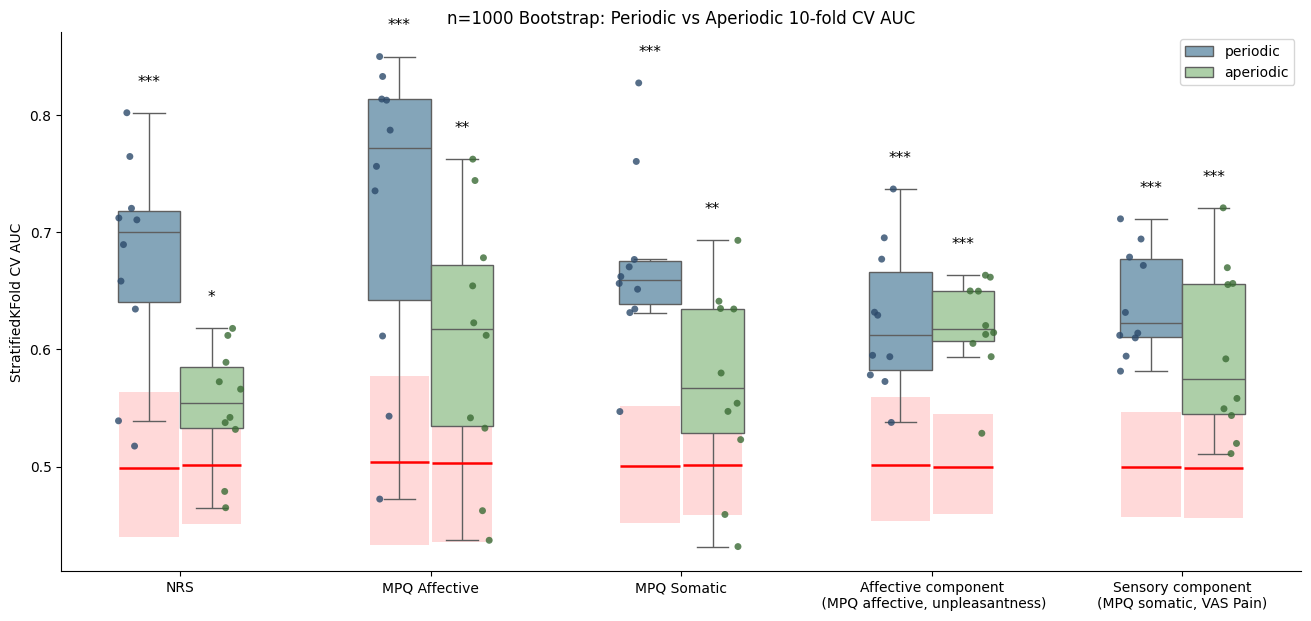

In [12]:
figdir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/metadata_nboot1000/zero_filling/plots'
metadir = '/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/metadata_nboot1000/zero_filling'
m = load_all_metadata(metadir)
import matplotlib.pyplot as plt
import seaborn as sns
long_df = m['fold_table'][['behavior', 'feature_type', 'fold', 'auc']].dropna()
behavior_order = ['nrs', 'mpq_affective', 'mpq_somatic','affective_pc1','sensory_pc1']
behavior_labels = {'nrs': 'NRS', 'mpq_affective': 'MPQ Affective', 'mpq_somatic': 'MPQ Somatic','affective_pc1':'Affective component\n (MPQ affective, unpleasantness)','sensory_pc1':'Sensory component\n(MPQ somatic, VAS Pain)'}
long_df = long_df[long_df['behavior'].isin(behavior_order)].copy()
long_df['behavior'] = pd.Categorical(long_df['behavior'], categories=behavior_order, ordered=True)
long_df = long_df.sort_values('behavior')

feature_type_order = ['periodic', 'aperiodic']
colors = {'periodic': '#7BA7C2', 'aperiodic': '#A8D5A2'}

fig, ax = plt.subplots(figsize=(16, 7))

sns.boxplot(
    data=long_df, x='behavior', y='auc', hue='feature_type',
    order=behavior_order, hue_order=feature_type_order,
    palette=colors, fliersize=0, width=0.5,
    ax=ax
)
sns.stripplot(
    data=long_df, x='behavior', y='auc', hue='feature_type',
    order=behavior_order, hue_order=feature_type_order,
    dodge=True, jitter=True, size=5, alpha=0.8,
    palette={'periodic': '#2C4A6B', 'aperiodic': '#3A6B34'},
    edgecolor='none', ax=ax, legend=False
)


from matplotlib.lines import Line2D
from matplotlib.patches import Patch
permutation_5behav=pd.read_pickle('/home/hazel/shirvalkar/test-code-hazel/logreg_results_pickle/NEW1023_NOPCA_10fold_pooled_5behavior_BOOTSTRAP_permutation_baseline_auc.pickle')        
perm_df = permutation_5behav

n_hue = len(feature_type_order)
box_width = 0.5
dodge_offset = box_width / n_hue / 2
half = box_width / n_hue / 2 * 0.95
x_positions = {b: i for i, b in enumerate(behavior_order)}

def p_to_stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'

for _, row in perm_df.iterrows():
    if row['behavior'] not in x_positions:
        continue
    sign = -1 if row['feature_type'] == 'periodic' else 1
    xc = x_positions[row['behavior']] + sign * dodge_offset

    ax.fill_between([xc - half, xc + half], row['null_95th_low'], row['null_95th_high'],
                    color='red', alpha=0.15, zorder=1, lw=0)
    ax.hlines(row['null_mean'], xc - half, xc + half, color='red', lw=1.8, zorder=5)

    sub = long_df[(long_df['behavior'] == row['behavior']) & (long_df['feature_type'] == row['feature_type'])]
    ax.text(xc, sub['auc'].max() + 0.02, p_to_stars(row['p_perm']),
            ha='center', va='bottom', fontsize=11)

handles, labels = ax.get_legend_handles_labels()
extra = [Line2D([0], [0], color='red', lw=1.8, label='Permutation null mean'),
         Patch(facecolor='red', alpha=0.15, label='Permutation null 95% interval')]
ax.legend(handles[:2] + extra, labels[:2] + [e.get_label() for e in extra],
          loc='upper right', frameon=True)

ax.set_ylabel('StratifiedKFold CV AUC')
ax.set_xlabel('')
ax.set_xticklabels([behavior_labels[b] for b in behavior_order])
ax.set_title('n=1000 Bootstrap: Periodic vs Aperiodic 10-fold CV AUC')
ax.spines[['top', 'right']].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2], labels[:2], loc='upper right', frameon=True)


In [11]:
from scipy.stats import wilcoxon, ttest_rel, ttest_1samp, ttest_ind
long_df_patient_avg = long_df
for behav in behavior_order:
    sub = long_df_patient_avg[long_df_patient_avg['behavior'] == behav]
    # periodic_vals = sub[sub['feature_type']=='periodic'].set_index('ptID')['auc']
    # aperiodic_vals = sub[sub['feature_type']=='aperiodic'].set_index('ptID')['auc']
    
    periodic_vals = sub[sub['feature_type']=='periodic']['auc']
    aperiodic_vals = sub[sub['feature_type']=='aperiodic']['auc']
    statp, pp = ttest_1samp(periodic_vals, 0.5)
    statap, pap = ttest_1samp(aperiodic_vals, 0.5)
        
    stat2, p2 = ttest_ind(periodic_vals, aperiodic_vals)
    print(f'For {behav}: periodic vs 0.5 ttest p={pp:.4f}, aperiodic vs 0.5 ttest p={pap:.4f}, periodic vs aperiodic ttest p={p2:.4f}, ')

    # common_pts = periodic_vals.index.intersection(aperiodic_vals.index)
    # periodic_vals = periodic_vals.loc[common_pts]
    # aperiodic_vals = aperiodic_vals.loc[common_pts]

    # if len(common_pts) >= 3:
    #     stat, p = wilcoxon(periodic_vals, aperiodic_vals)
    #     print(f'{behav}: n={len(common_pts)} patients, Wilcoxon p={p:.4f}')

For nrs: periodic vs 0.5 ttest p=0.0003, aperiodic vs 0.5 ttest p=0.0061, periodic vs aperiodic ttest p=0.0068, 
For mpq_affective: periodic vs 0.5 ttest p=0.0005, aperiodic vs 0.5 ttest p=0.0008, periodic vs aperiodic ttest p=0.0834, 
For mpq_somatic: periodic vs 0.5 ttest p=0.0001, aperiodic vs 0.5 ttest p=0.0263, periodic vs aperiodic ttest p=0.0111, 
For affective_pc1: periodic vs 0.5 ttest p=0.0001, aperiodic vs 0.5 ttest p=0.0000, periodic vs aperiodic ttest p=0.9680, 
For sensory_pc1: periodic vs 0.5 ttest p=0.0000, aperiodic vs 0.5 ttest p=0.0019, periodic vs aperiodic ttest p=0.1231, 


,behav,ROI,Feature,Coefficient,Folds Consistent
0,nrs,L IC,beta,-0.473813,10.0
1,nrs,L Caudate,beta,0.325301,10.0
2,nrs,R MCC,alpha,-0.300048,10.0
3,nrs,R Caudate,theta,0.278522,10.0
4,nrs,R AINS,theta,-0.268808,8.0
5,nrs,R MCC,delta,-0.243312,10.0
6,nrs,L MCC,alpha,0.233013,6.0
7,nrs,R Caudate,low_gamma,0.216868,10.0
8,nrs,L AINS,low_gamma,0.208306,10.0
9,nrs,L AINS,beta,-0.191268,10.0


,behav,ROI,Feature,Coefficient,Folds Consistent
0,nrs,L dlPFC,exponent_z,0.002543,10.0
1,nrs,R dlPFC,exponent_z,0.001753,10.0
2,nrs,R THAL,exponent_z,0.001634,10.0
3,nrs,L MCC,exponent_z,0.001536,10.0
4,nrs,R AINS,exponent_z,0.001484,10.0
5,nrs,R MCC,offset_z,0.001476,10.0
6,nrs,R MCC,exponent_z,0.001392,10.0
7,nrs,L dlPFC,offset_z,0.001376,10.0
8,nrs,R Caudate,exponent_z,0.001275,10.0
9,nrs,L dmPFC,exponent_z,0.001222,10.0


,behav,ROI,Feature,Coefficient,Folds Consistent
0,mpq_affective,L dlPFC,beta,0.003237,10.0
1,mpq_affective,R MCC,beta,0.003183,10.0
2,mpq_affective,R AINS,alpha,0.002976,10.0
3,mpq_affective,L AINS,theta,0.002944,10.0
4,mpq_affective,L MCC,beta,0.002747,10.0
5,mpq_affective,L dlPFC,theta,0.002706,10.0
6,mpq_affective,L dmPFC,theta,0.002538,10.0
7,mpq_affective,L MCC,theta,0.002509,10.0
8,mpq_affective,L dmPFC,alpha,0.002501,10.0
9,mpq_affective,R MCC,alpha,0.002438,10.0


,behav,ROI,Feature,Coefficient,Folds Consistent
0,mpq_affective,L dmPFC,exponent_z,3.281009,10.0
1,mpq_affective,L IC,offset_z,2.765623,8.0
2,mpq_affective,L dmPFC,offset_z,-2.602347,7.0
3,mpq_affective,L IC,exponent_z,-2.512027,10.0
4,mpq_affective,R dmPFC,exponent_z,2.274117,10.0
5,mpq_affective,L AINS,exponent_z,-2.244638,8.0
6,mpq_affective,R dmPFC,offset_z,-2.159064,7.0
7,mpq_affective,L Caudate,offset_z,-2.011781,10.0
8,mpq_affective,L dlPFC,offset_z,-1.914188,7.0
9,mpq_affective,R THAL,exponent_z,1.733617,10.0


,behav,ROI,Feature,Coefficient,Folds Consistent
0,mpq_somatic,L dlPFC,alpha,-0.957692,10.0
1,mpq_somatic,R AINS,theta,-0.849386,10.0
2,mpq_somatic,R AINS,beta,0.735178,10.0
3,mpq_somatic,R Caudate,theta,0.733292,10.0
4,mpq_somatic,L MCC,alpha,0.688719,10.0
5,mpq_somatic,L IC,beta,-0.665290,10.0
6,mpq_somatic,R IC,low_gamma,-0.659968,10.0
7,mpq_somatic,L dlPFC,theta,0.589776,10.0
8,mpq_somatic,R IC,beta,0.589655,10.0
9,mpq_somatic,R Caudate,low_gamma,0.577677,10.0


,behav,ROI,Feature,Coefficient,Folds Consistent
0,mpq_somatic,L THAL,offset_z,0.002717,10.0
1,mpq_somatic,R dlPFC,exponent_z,0.002701,10.0
2,mpq_somatic,L THAL,exponent_z,0.002444,10.0
3,mpq_somatic,L dlPFC,exponent_z,0.002395,10.0
4,mpq_somatic,R THAL,exponent_z,0.002214,10.0
5,mpq_somatic,R AINS,exponent_z,0.002142,10.0
6,mpq_somatic,R AINS,offset_z,0.001873,10.0
7,mpq_somatic,R THAL,offset_z,0.001865,10.0
8,mpq_somatic,L MCC,exponent_z,0.001636,10.0
9,mpq_somatic,R dlPFC,offset_z,0.001526,10.0


,behav,ROI,Feature,Coefficient,Folds Consistent
0,affective_pc1,L PINS,low_gamma,-0.353714,10.0
1,affective_pc1,R AINS,theta,-0.323291,6.0
2,affective_pc1,L dlPFC,beta,0.323090,10.0
3,affective_pc1,R IC,theta,0.322660,10.0
4,affective_pc1,L MCC,theta,0.319142,10.0
5,affective_pc1,R MCC,delta,-0.307214,7.0
6,affective_pc1,L dmPFC,beta,-0.306432,10.0
7,affective_pc1,R dmPFC,delta,0.305028,10.0
8,affective_pc1,R MCC,alpha,-0.289157,6.0
9,affective_pc1,L dlPFC,low_gamma,0.284175,10.0


,behav,ROI,Feature,Coefficient,Folds Consistent
0,affective_pc1,R dlPFC,exponent_z,0.009722,10.0
1,affective_pc1,L dlPFC,exponent_z,0.007829,10.0
2,affective_pc1,L THAL,exponent_z,0.006440,10.0
3,affective_pc1,L MCC,exponent_z,0.005837,10.0
4,affective_pc1,L IC,exponent_z,0.005821,10.0
5,affective_pc1,L dmPFC,exponent_z,0.005609,10.0
6,affective_pc1,R MCC,exponent_z,0.005498,10.0
7,affective_pc1,R Caudate,exponent_z,0.005293,10.0
8,affective_pc1,L IC,offset_z,0.005287,10.0
9,affective_pc1,R AINS,exponent_z,0.004908,10.0


,behav,ROI,Feature,Coefficient,Folds Consistent
0,sensory_pc1,R AINS,theta,-0.978268,10.0
1,sensory_pc1,L IC,beta,-0.830205,10.0
2,sensory_pc1,L MCC,alpha,0.764867,10.0
3,sensory_pc1,L dlPFC,alpha,-0.759305,10.0
4,sensory_pc1,R MCC,alpha,-0.756041,10.0
5,sensory_pc1,R IC,beta,0.747851,10.0
6,sensory_pc1,L PINS,low_gamma,-0.690934,10.0
7,sensory_pc1,L dlPFC,beta,0.667211,10.0
8,sensory_pc1,R Caudate,low_gamma,0.666885,10.0
9,sensory_pc1,R AINS,delta,0.635334,10.0


,behav,ROI,Feature,Coefficient,Folds Consistent
0,sensory_pc1,R dlPFC,exponent_z,0.014288,10.0
1,sensory_pc1,L dlPFC,exponent_z,0.010280,10.0
2,sensory_pc1,R AINS,exponent_z,0.009001,10.0
3,sensory_pc1,L MCC,exponent_z,0.008979,10.0
4,sensory_pc1,R THAL,exponent_z,0.008794,10.0
5,sensory_pc1,L THAL,offset_z,0.006798,10.0
6,sensory_pc1,L dmPFC,exponent_z,0.006505,10.0
7,sensory_pc1,L THAL,exponent_z,0.006378,10.0
8,sensory_pc1,R IC,offset_z,0.006320,10.0
9,sensory_pc1,R MCC,offset_z,0.006249,10.0


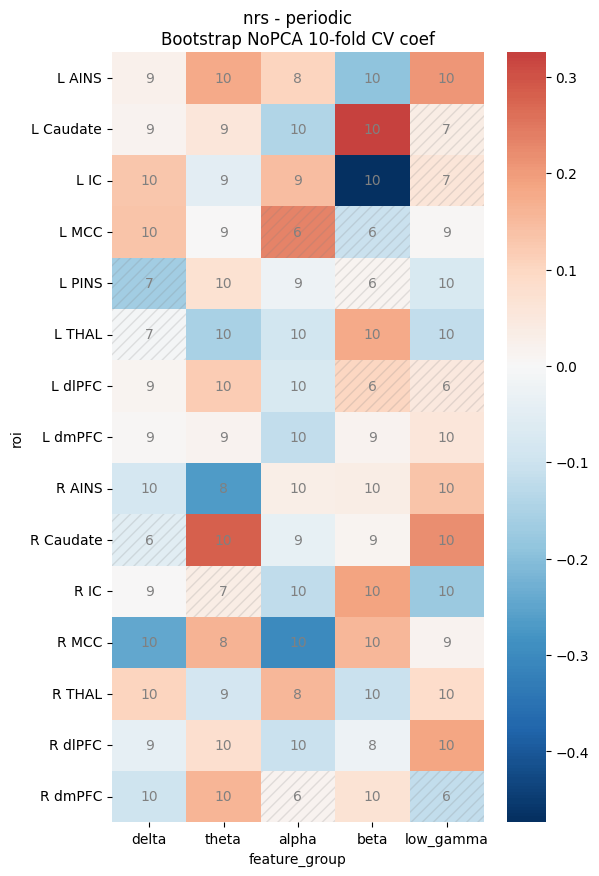

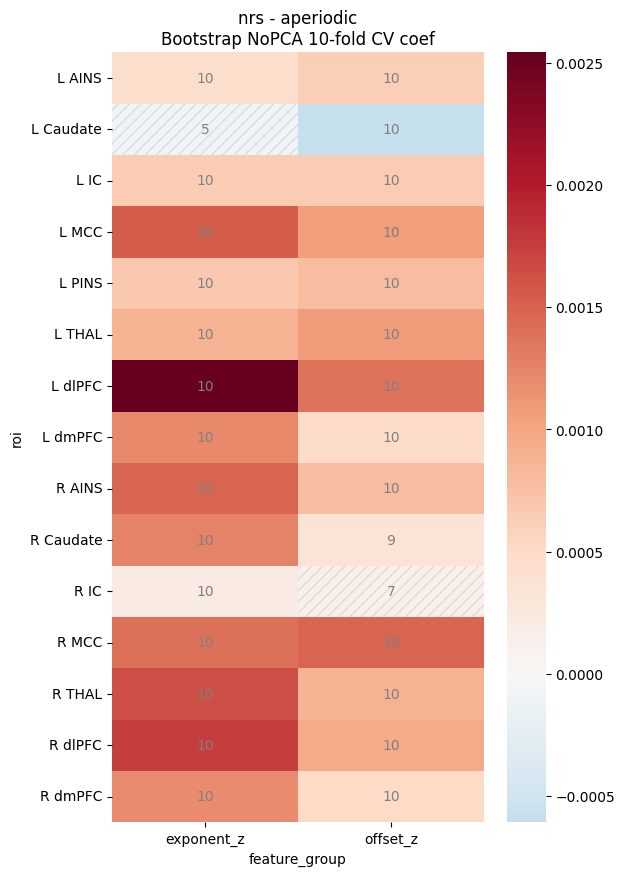

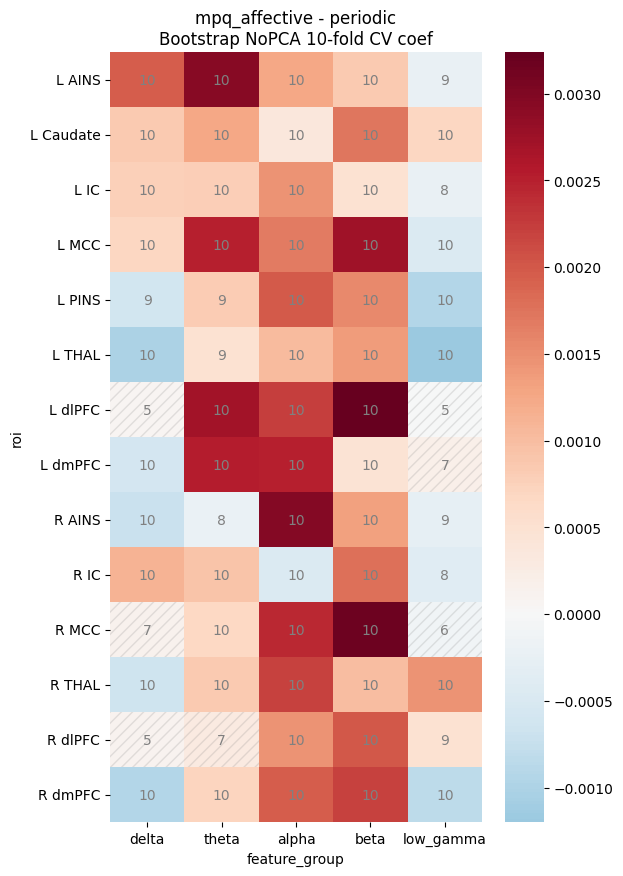

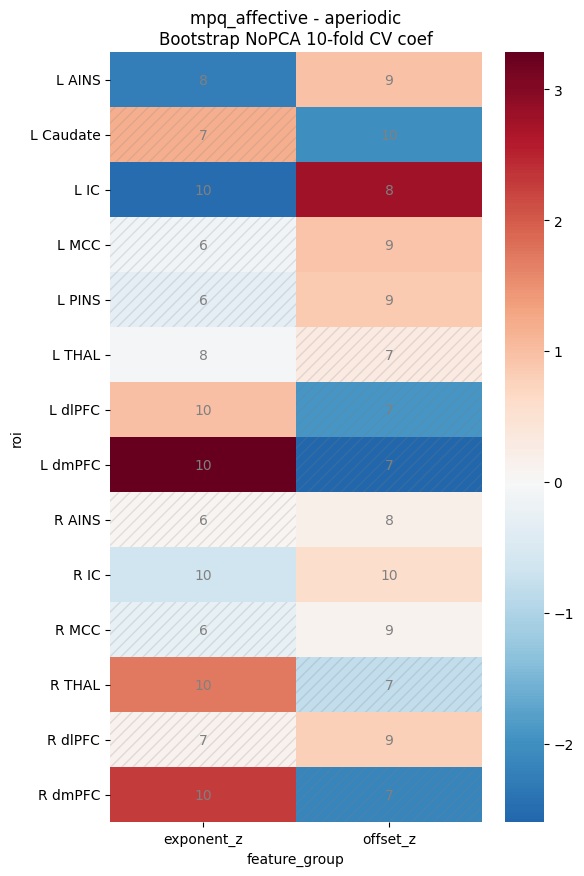

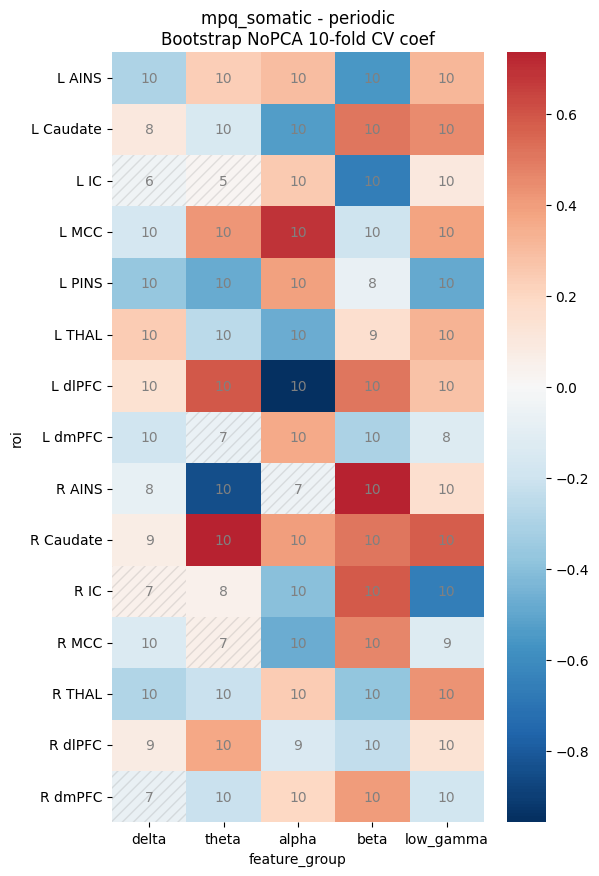

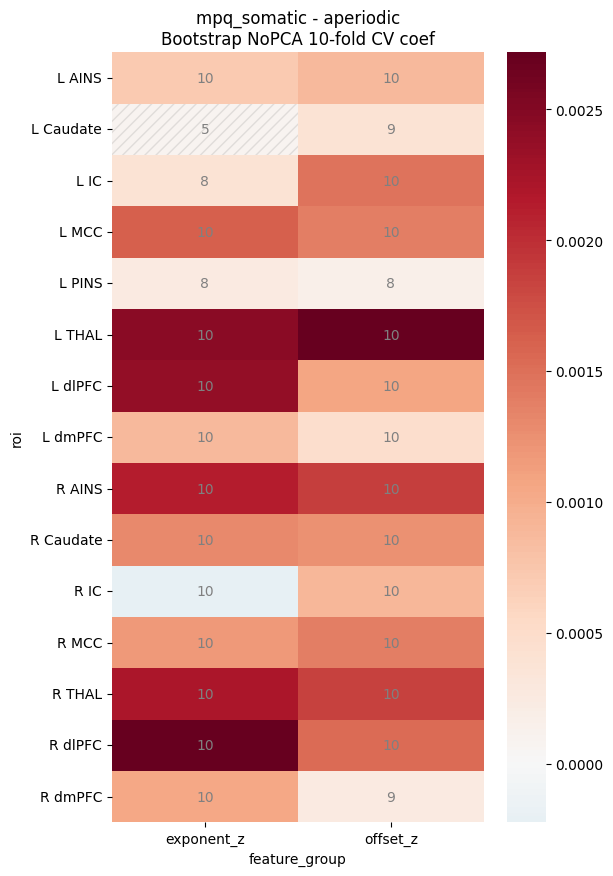

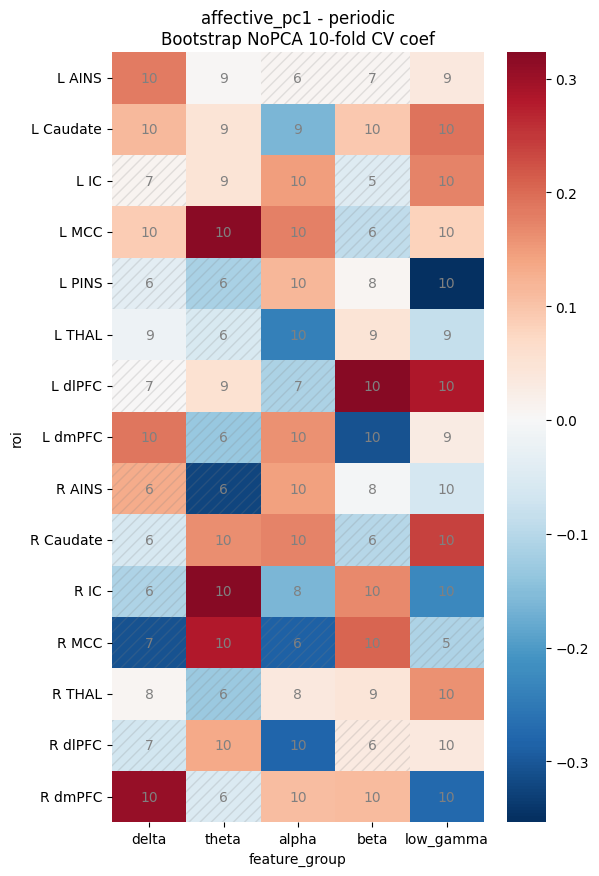

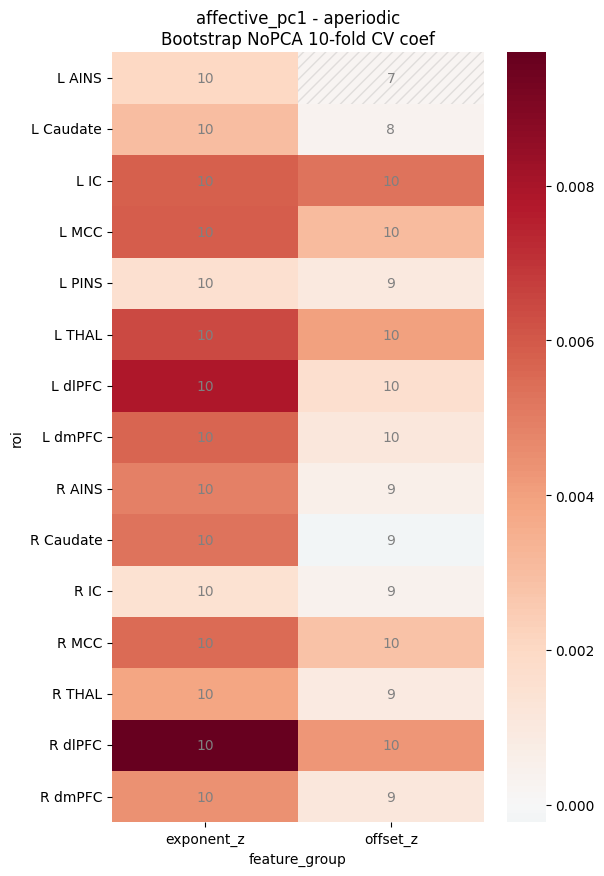

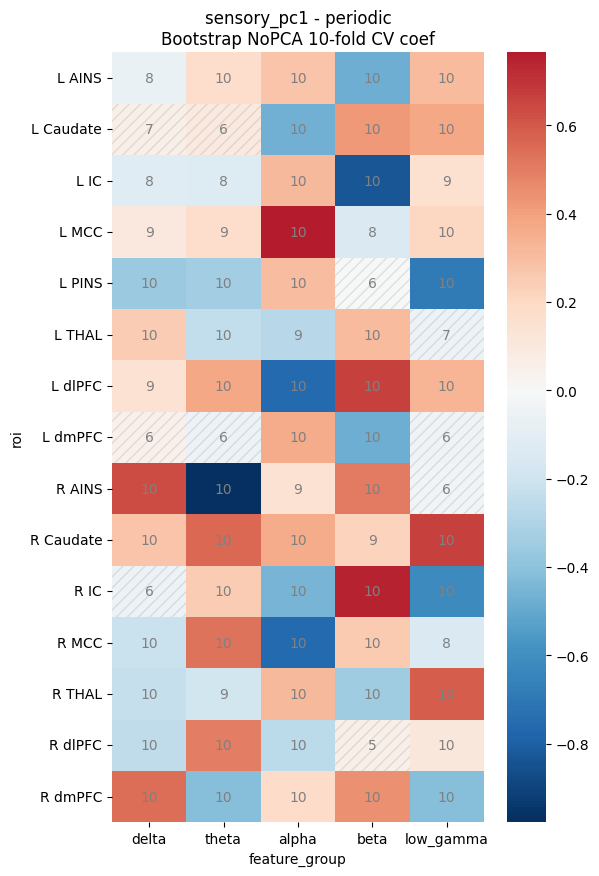

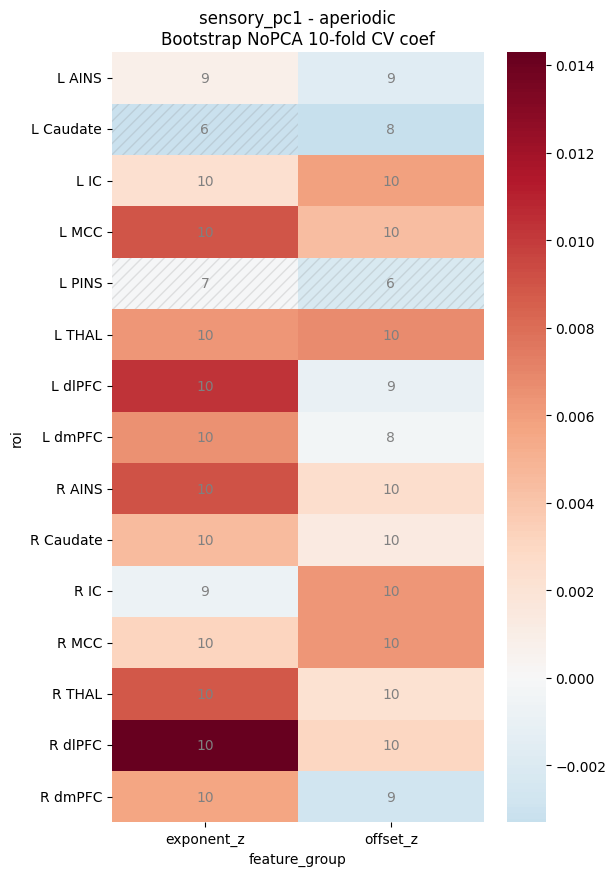

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
target_behavs = behavior_configs.keys()
target_features = ['periodic','aperiodic']
stability_all_behaviors = pd.read_pickle(f'{metadir}/NEW1118_NOPCA_10fold_pooled_5behavior_BOOTSTRAP_ZEROFILLING_stability.pickle')
auc_summary_all_behaviors = pd.read_pickle(f'{metadir}/NEW1118_NOPCA_10fold_pooled_5behavior_BOOTSTRAP_ZEROFILLING_auc_summary.pickle')

stability_all_behaviors['roi'] = [s.split('_')[-1] for s in stability_all_behaviors['feature']]
stability_all_behaviors['feature_group'] = [re.match(r'^[a-z_]*', s).group()[:-1] for s in stability_all_behaviors['feature']]
# display(stability_all_behaviors.head(5))
for target_behav in target_behavs:
    for target_feature in target_features:
        subset = stability_all_behaviors[(stability_all_behaviors['behavior']==target_behav) & (stability_all_behaviors['feature_type']==target_feature)]
        if target_feature=='periodic':  
            coef=subset.pivot(columns="feature_group",index="roi",values="cv_mean_coef").reindex(columns=bands) 
            sign_consistency=subset.pivot(columns="feature_group",index="roi",values="sign_consistency").reindex(columns=bands)
        else:  
            coef=subset.pivot(columns="feature_group",index="roi",values="cv_mean_coef").reindex(columns=metrics)
            sign_consistency=subset.pivot(columns="feature_group",index="roi",values="sign_consistency").reindex(columns=metrics)

        same_sign_folds = sign_consistency * 5 + 5

        ranked = coef.abs().stack().sort_values(ascending=False)
        top_features = ranked.iloc[:15].index

        # Create a table with actual coefficients and fold consistency
        top_table = pd.DataFrame([
            {
                'behav': target_behav,
                'ROI': roi,
                'Feature': feature,
                'Coefficient': coef.loc[roi, feature],
                'Folds Consistent': same_sign_folds.loc[roi, feature]
            }
            for roi, feature in top_features
        ])

        display(top_table)
        plt.figure(figsize=(6,10))
        ax=sns.heatmap(coef,cmap='RdBu_r',center=0)

        threshold=0.6
        for i in range(sign_consistency.shape[0]):
            for j in range(sign_consistency.shape[1]):
                if not np.isnan(same_sign_folds.iloc[i,j]):
                    ax.text(j+0.5,i+0.5,f"{same_sign_folds.iloc[i,j]:.0f}",ha='center',va='center',color='gray')
                if sign_consistency.iloc[i,j] < threshold:
                    ax.add_patch(plt.Rectangle((j,i),1,1,fill=False,alpha=0.2,edgecolor='gray',hatch='///',linewidth=0))

        plt.title(f"{target_behav} - {target_feature}\nBootstrap NoPCA 10-fold CV coef")
        plt.savefig(f"/home/hazel/shirvalkar/test-code-hazel/coefficient_analysis_figure/reversed_label(positive_as_high)_10012026/metadata_nboot1000/zero_filling/plots/coef/PCA(none) - {target_behav} - {target_feature} - 10foldCVCoef")